## Stress calculation and fracturing

Below are the functions you created in previous parts.

In [11]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
import random
import json

e = 0.03 #relaxation threshold
k = 1.0 #spring constant
l = 1.5 #equilibrium distance this is initially 2 in the lattice but is set to 1 for the simulation
n = 100 # size of the array
fover = 1.1 #over relaxation scale

lattice = np.zeros([n,n,2,1]) #array with particle positions [0] = x, [1] = y
adjacent = np.zeros([n,n]).tolist() #array with list of neighbour particles
stress = np.zeros([n,n,3,1]) #sxx[0], syy[1], sxy[2] stress per particle 


In [12]:
def triangular():
    global lattice
    for i in range(n):
        for j in range(n):
            if (i%2==0 and j%2==0) or (i%2==1 and j%2==1):
                lattice[i][j][0] = i*math.sqrt(3)+2
                lattice[i][j][1] = j+2

In [13]:
def circle():
    global lattice
    for i in range(n):
        for j in range(n):
            length = math.sqrt((i-49)**2 + (j-49)**2)
            if length <= 10:
                lattice[i][j][0] = 0
                lattice[i][j][1] = 0

In [14]:
def adjacent_particles():
    global adjacent
    neighbours = [(-1,-1),(-1,1),(0,-2),(0,2),(1,-1),(1,1)]
    for i in range(2,n-2):
        for j in range(2,n-2):
            if lattice[i][j].all() != 0:
                adjacent[i][j] = []
                for nb in neighbours:
                    if (i+nb[0]>-1 and i+nb[0]<n) and (j+nb[1]>-1 and j+nb[1]<n):
                        if lattice[i+nb[0]][j+nb[1]].all() !=0:
                            adjacent[i][j].append((i+nb[0],j+nb[1]))


In [15]:
def force(i, j): 
    global stress, lattice #this will allow you to access and modify the variables declared outside this function
    xx, yy, sxx, syy, sxy, anc = 0, 0, 0, 0, 0, 0 
    
# distance between 2 particles 

    for nb in adjacent[i][j]:
        dx = lattice[i][j][0]-lattice[nb[0]][nb[1]][0]
        dy = lattice[i][j][1]-lattice[nb[0]][nb[1]][1]
        dd = math.sqrt(dx**2 + dy**2)


        if (dd != 0):
            uxi = dx/dd
            uyi = dy/dd

        else:  
            uxi = 0.0
            uyi = 0.0

        fn = -k*(dd-l)
        fx = fn*uxi
        fy = fn*uyi
        
# overall force and stress
        xx = xx + fx
        yy = yy + fy
        sxx = sxx + fx*(l/2)*uxi
        syy = syy + fy*(l/2)*uyi
        sxy = sxy + fx*(l/2)*uyi
        anc = anc + k

    stress[i][j][0] = sxx
    stress[i][j][1] = syy
    stress[i][j][2] = sxy
    
# over relaxation step       
    
    anc = 1.0/anc
    xx = xx * anc        
    yy = yy * anc
        
    if (e < math.sqrt((xx*xx)+(yy*yy))): 
        lattice[i][j][0] = lattice[i][j][0] + xx * fover   
        lattice[i][j][1] = lattice[i][j][1] + yy * fover  
       

In [16]:
def run_simulation():
    for z in range(2): #number of time steps
        for i in range(2,n-2): # leaving the fixed borders out
            for j in range(2,n-2):
                if lattice[i][j].all()!=0:
                    force(i, j)

In [17]:
def stress_calculation():
    global diff_stress, mean_stress
    for i in range(2,n-2): 
        for j in range(2,n-2):
            if lattice[i][j].all()!=0:
                smax = ((stress[i][j][0] + stress[i][j][1]) / 2.0) + math.sqrt(((stress[i][j][0] - stress[i][j][1]) / 2.0) * ((stress[i][j][0] - stress[i][j][1]) / 2.0) + stress[i][j][2] * stress[i][j][2])
                smin = ((stress[i][j][0] + stress[i][j][1]) / 2.0) - math.sqrt(((stress[i][j][0] - stress[i][j][1]) / 2.0) * ((stress[i][j][0] - stress[i][j][1]) / 2.0) + stress[i][j][2] * stress[i][j][2])
                diff_stress[i][j] = smax - smin
                mean_stress[i][j] = (smax + smin)/2

### Part 3 - Fracturing 

Your task is to create a fracturing function that will select one spring from the lattice to break in each loop. The function should calculate fn the same way as the force function. It should then check if fn is bigger or equal to 0. If yes, it calculates ten_break = (fn/tb) + var_i. Var_i is a random number between -0.8 and 0.8 generated using random.uniform(-0.8 , 0.8). To pass the test use the random numbers from the given array called var. Once you do, you can replace var_i with the random.uniform function to create different results.<br>
After calculating ten_break, check if it is bigger than 1, if it is, also compare it to mbreak. If it is greater than mbreak, save the 2 particles: (i,j) and nb as the position where the spring should break. Every time you discover a ten_break that is greater than the current mbreak choose a new spring_to_break along with spring_x and spring_y (i and j). 

In [18]:
lattice = np.zeros([n,n,2,1])
stress = np.zeros([n,n,3,1])
triangular()
adjacent_particles()
var = np.loadtxt("tests/variation.txt").reshape(50,100,100)
var_i = 0 

In [19]:
#Task 1
def fracturing(i,j):
    global mbreak, spring_to_break, spring_x, spring_y
    tb = 1
    ten_break = 0

    for nb in adjacent[i][j]:
        dx = lattice[i][j][0]-lattice[nb[0]][nb[1]][0]
        dy = lattice[i][j][1]-lattice[nb[0]][nb[1]][1]
        dd = math.sqrt(dx**2 + dy**2)
        
        fn = k*(dd-l)     
        
        if (fn >= 0.0):
            ten_break = (fn / tb) + var_i
            
        if (ten_break > 1.0): 
            if (ten_break > mbreak):  
                mbreak = ten_break 
                spring_to_break = nb
                spring_x = i
                spring_y = j



Each loop (50 steps) should first do over relaxation (2 steps) and then loop over the lattice array to find the spring to break. Once the fracturing finishes, delete the spring from the adjacent array. Remember that each of the positions in the adjacent array has a list of values like this: [(11, 11), (11, 13), (12, 10), (12, 14), (13, 11), (13, 13)]. <br>
If spring_to_break = (11, 11) then typing adjacent[12][12].remove(spring_to_break) will remove (11,11) from the list of adjacent particles. You will need to do the same thing for the particle at (11,11) removing (12,12). Since these are lists of tuples, if you save each coordinate separately then you need to add extra brackets in the remove statement. <br>
After iterating over the lattice array, the fracturing function should have selected a spring to break. Do not delete springs between particles and boundaries. If the selected neighbour is a boundary then it has no list of neighbours in the adjacent array and the entry is equal to 0.

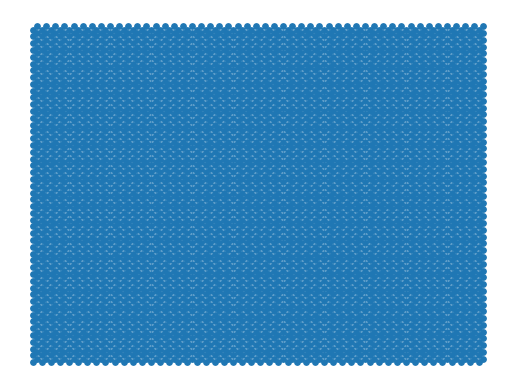

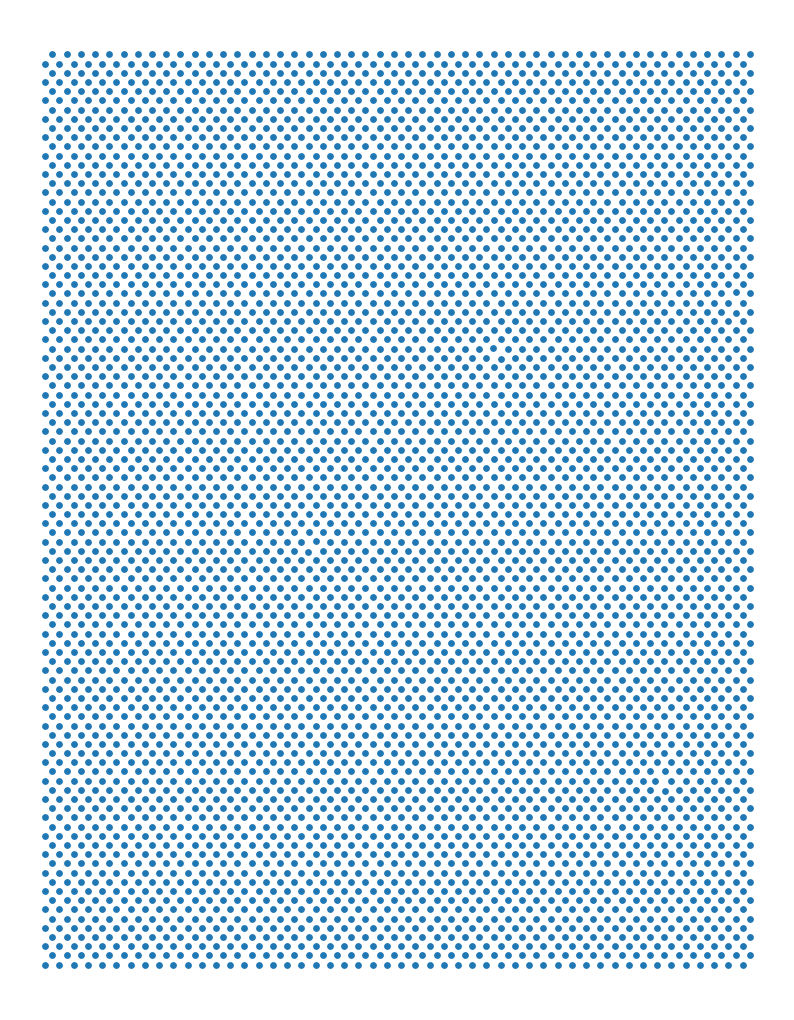

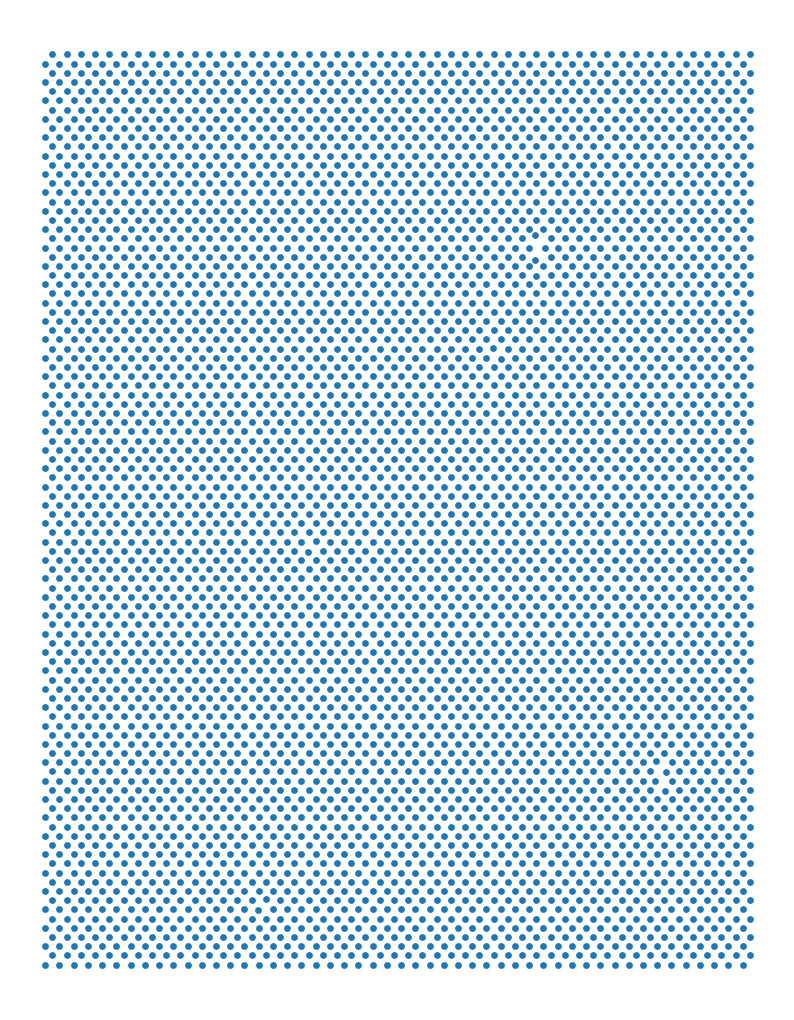

In [ ]:
#Task 2
for h in range(50):
    mbreak = 0
    spring_to_break = 0
    spring_x, spring_y = 0, 0
    # using var_i = var[h][i][j] while iterating over the array will give you a new value of var_i
    
    run_simulation()
    
    for i in range(2,n-2): 
        for j in range(2,n-2):
            var_i = var[h][i][j]
            if lattice[i][j].all()!=0:
                fracturing(i, j)
                
    if (spring_to_break != 0):
        
        for nb in adjacent[spring_x][spring_y]:
            if (adjacent[nb[0]][nb[1]] != 0.0): # if nb = 0.0 then its wall
                if nb == spring_to_break:
                    adjacent[nb[0]][nb[1]].remove((spring_x,spring_y))
                    adjacent[spring_x][spring_y].remove(nb)

    
    # make a plot every 5 steps
    if (h%5==0):
        x = lattice[:, :, 0]
        x = x[x!=0]
        y = lattice[:, :, 1]
        y = y[y!=0]

        plt.axis('off')
        plt.rcParams["figure.figsize"] = (10,13)
        plt.scatter(x, y, s = 15)
        plt.show()

In [ ]:
t_lattice = np.loadtxt("tests/testsolve10.txt")
if (np.array_equal(lattice.reshape(100*100*2*1), t_lattice)):
    print("Passed testcase 10")
else:
    print("Failed testcase 10")

In [ ]:
#data frame for stress plots

diff_stress = np.zeros([n,n])
mean_stress = np.zeros([n,n])
stress_calculation()

x = lattice[2:n-2, 2:n-2, 0].flatten()
y = lattice[2:n-2, 2:n-2, 1].flatten()
diff_stress = diff_stress[2:n-2, 2:n-2].flatten()
diff_stress = diff_stress[x!=0]

mean_stress = mean_stress[2:n-2, 2:n-2].flatten()
mean_stress = mean_stress[x!=0]

df = pd.DataFrame({'x': x[x!=0],
                   'y': y[y!=0],
                   'Differential stress': diff_stress,
                   'Mean stress': mean_stress})

In [ ]:
df.plot.scatter('x', 'y', s=15, c='Differential stress', cmap='RdPu')
plt.axis('off')
plt.show()

In [ ]:
df.plot.scatter('x', 'y', s=15, c='Mean stress', cmap='YlOrRd')
plt.axis('off')
plt.show()

### Extra example
A high number of steps can take longer to run. You can use the data set below to explore fractures created over 2000 steps. Remove the '#' to load the lattice with the corresponding adjacency array and plot it. Do a stress calculation, then create a new data frame or run the 3 cells above to make the stress plots. You can also experiment with changing the equilibrium length and force calculation.

In [ ]:
#lattice = np.loadtxt('tests/lattice2000steps.txt').reshape(100, 100, 2, 1)
#with open("adj.txt", "r") as fp:
#   adjacent = json.load(fp)

In [ ]:
x = lattice[:, :, 0]
x = x[x!=0]
y = lattice[:, :, 1]
y = y[y!=0]

plt.axis('off')
plt.rcParams["figure.figsize"] = (10,13)
plt.scatter(x, y, s = 15)
plt.show()

### Part 4 - Hydrofracture

In this part you will create factures using fluid pressure. 

In [ ]:
l = 2.0
lattice = np.zeros([n,n,2,1])
stress = np.zeros([n,n,3,1])
triangular()
adjacent_particles()
n1 = 170 # shape of the fluid array is n1 x n

squares = {} # dictionary to remember the pressure sites with matching x and y gradients and the cells from fluid0 array they are made of 
belongsTo = np.zeros([n,n]).tolist() # array that matches each particle in the lattice to a pressure square


The two cells below use code from the heat diffusion exercise. First assigning high presure to a selected area and then performing diffusion.

In [ ]:
#diffusion set up
dx = dy = 0.1
D = 5
low, high = 0, 7 #pressure values

fluid0 = np.full([n1,n], low) # pressure array
fluid = fluid0.copy()

dx2, dy2 = dx*dx, dy*dy
dt = dx2 * dy2 / (2 * D * (dx2 + dy2))

# Initial conditions - circle of radius r2 centred at (cx,cy)
cx, cy = 85, 50
r2 = 15
for i in range(n1):
    for j in range(n):
        p2 = (i-cx)**2 + (j-cy)**2
        if p2 < r2:
            fluid0[i,j] = high

In [ ]:
# function used in heat diffusion exercise
def pressure_diffusion(u0, u):
    for i in range(1,n1-1):
        for j in range(1,n-1):
            u[i,j] = u0[i,j] + D * dt * (
                (u0[i+1, j] - 2*u0[i, j] + u0[i-1,j])/dx2
              + (u0[i, j+1] - 2*u0[i, j] + u0[i, j-1])/dy2)           
    u0 = u.copy()
    
    return u0, u

Each 4 neighbouring cells in the fluid array connect to create a pressure square. To remember these squares use a dictionary whose keys are the coordinates of the top left corner and the bottom right corner of each square. A key points to pressure gradients for x and y and a list of array coordinates for the fluid array to calculate the gradients from. <br>
A key looks like this : (x1, y1, x2, y2) <br>
Your first task is to construct the dictionary with correct key coordinates. At the start 'Px' and 'Py' should be set to 0 and 'cells' should be a list of the four indexes that make up the blue square.<br>

<br>
To create the dictionary use the following syntax: <br>
* a new entry in a dictionary: squares[key] = value <br>
However, squares is a nested dictionary, that means calling squares[key] will return another dictionary with following values: Px, Py and cells. <br>
* a new entry in a nested dictionary: squares[key] = {key: value, key: value, key: value} <br> 



This picture shows the fluid array. The blue square is a pressure square, Pn stands for pressure in a particular array cell. The order in which you save these to the dictionary is important later for calculating the gradient. 
<img src="files/tests/pressure_square.png">

All squares have size 1 and blue squares are shifted by 0.5 compared to the fluid lattice. Use i and j from for loops to get the x and y coordinates. All of them also need to be shifted by 2 to match the original lattice with particles.
<img src="files/tests/pressure_square_detail.png">

In [ ]:
# Task 3: fill in the key coordinates, each key needs to follow this order: x1, y1, x2, y2
for i in range(0,n1-1):
    for j in range(0,n-1):
        squares[#add ( x1, y1, x2, y2) here]  = {'Px':0, 'Py':0, 'cells': [[i,j],[i+1,j],[i,j+1],[i+1,j+1]]} # cells array stores indexes for fluid0 array to access the pressure values

In [ ]:
#the following test checks the squares dictionary key construction
square_keys = []
for key in squares.keys():
    square_keys.append([key]) 
square_keys = np.array(square_keys)

In [ ]:
square_keys_1 = np.loadtxt("tests/testsolve11.txt")
if (np.array_equal(square_keys_1, square_keys.reshape(16731*4))):
    print("Passed testcase 11")
else:
    print("Failed testcase 11")

Your next task is to make a function that calculates Px and Py for each square in the dictionary. The for loop iterates over the dictionary keys, so that squares[key] will give you Px, Py and cells at once. If you want to get just the cells list you can do squares[key]['cells']. The same works with Px and Py.<br> 
Update the Px and Py in the dictionary by calculating the following: <br> 
* Px = ((P0 - P1) + (P2 - P3)) / 2 
* Py = ((P0 - P2) + (P1 - P3)) / 2 <br>
Use the indexes stored in 'cells' to get the pressure values in fluid0. <br>
(Note: This step is a bit tedious)

In [ ]:
# Task 4 
def pressure_gradient():
    global squares
    for key in squares.keys():
        #Px = 
        #Py = 

During each simulation loop you will need to assign each particle to a square. To find out which square a particle belongs to, first get the particle's coordinates. You can then round them and subtract or add 0.5 to create a key that will match the square dictionary. <br>
To get just the coordinate number add extra [0] after the lattice indexing like this lattice[i][j][0][0].

In [ ]:
# Task 5
def whichSquare():
    global belongsTo
    for i in range(2,n-2):
        for j in range(2,n-2):
            round_x = round(#round x)
            round_y = round(#round y)
            belongsTo[i][j] = (#x1, y1, x2, y2) 

You will need to modify the original force function slightly to account for the newly added pressure. Add the matching Px and Py gradients to xx and yy after the neigbour loop finishes. The square the particle belongs to is saved at the same index as the particle. You can find it in belongsTo array. This will give you a dictionary key with the correct square. From there you can get Px and Py. 

In [ ]:
def forceAndPressure(i, j): 
    global stress, lattice
    xx, yy, sxx, syy, sxy, anc = 0, 0, 0, 0, 0, 0 
    
# distance between 2 particles 

    for nb in adjacent[i][j]:
        dx = lattice[i][j][0]-lattice[nb[0]][nb[1]][0]
        dy = lattice[i][j][1]-lattice[nb[0]][nb[1]][1]
        dd = math.sqrt(dx**2 + dy**2)


        if (dd != 0):
            uxi = dx/dd
            uyi = dy/dd

        else:  
            uxi = 0.0
            uyi = 0.0

        fn = -k*(dd-l)
        fx = fn*uxi 
        fy = fn*uyi 
        
# overall force and stress
        xx = xx + fx
        yy = yy + fy
        sxx = sxx + fx*(l/2)*uxi
        syy = syy + fy*(l/2)*uyi
        sxy = sxy + fx*(l/2)*uyi
        anc = anc + k

    stress[i][j][0] = sxx
    stress[i][j][1] = syy
    stress[i][j][2] = sxy
    
# Task 6: add the pressure gradient to xx and yy 
    
    anc = anc + 1
    
# over relaxation step       
    
    anc = 1.0/anc
    xx = xx * anc        
    yy = yy * anc
        
    if (e < math.sqrt((xx*xx)+(yy*yy))): 
        lattice[i][j][0] = lattice[i][j][0] + xx * fover   
        lattice[i][j][1] = lattice[i][j][1] + yy * fover  

Finally, construct the simulation loop. First perform 2 steps of pressure diffusion. After that, update the pressure gradients and matching squares. Next do four steps of over relaxation using the modified function forceAndPressure. The last thing to do is to include the fracturing function and spring breaking.

In [ ]:
# Task 7 
for z in range(5): 
    for c in range (2):
    # diffusion
    
    # gradient and square assigning
    
    for w in range(4):
    # over relaxation
    
    mbreak = 0
    spring_to_break = 0
    spring_x, spring_y = 0, 0

    # fracture step
    

In [ ]:
x = lattice[:, :, 0]
x = x[x!=0]
y = lattice[:, :, 1]
y = y[y!=0]

plt.axis('off')
plt.rcParams["figure.figsize"] = (10,13)
plt.scatter(x, y, s = 15)
plt.show()

In [ ]:
t_lattice = np.loadtxt("tests/testsolve12.txt")
if (np.array_equal(lattice.reshape(100*100*2*1), t_lattice)):
    print("Passed testcase 12")
else:
    print("Failed testcase 12")

In [ ]:
diff_stress = np.zeros([n,n])
mean_stress = np.zeros([n,n])
stress_calculation()

x = lattice[2:n-2, 2:n-2, 0].flatten()
y = lattice[2:n-2, 2:n-2, 1].flatten()
diff_stress = diff_stress[2:n-2, 2:n-2].flatten()
diff_stress = diff_stress[x!=0]

mean_stress = mean_stress[2:n-2, 2:n-2].flatten()
mean_stress = mean_stress[x!=0]

df = pd.DataFrame({'x': x[x!=0],
                   'y': y[y!=0],
                   'Differential stress': diff_stress,
                   'Mean stress': mean_stress})

In [ ]:
df.plot.scatter('x', 'y', s=15, c='Differential stress', cmap='RdPu')
plt.axis('off')
plt.show()

In [ ]:
df.plot.scatter('x', 'y', s=15, c='Mean stress', cmap='YlOrRd')
plt.axis('off')
plt.show()